# Can we classify Wikipedia edits by intention?

A local, no-LLM look at English Wikipedia edits: who edits, what gets reverted, why patrollers say
they reverted it, and how far a free classifier on the diff gets. The corpus comes from
`uv run triage corpus` (see the README). It uses 24 one-hour windows spread over days 4–27 before
the anchor date, rotating the hour of day, and lists every article (ns0) edit in each window,
bots included. Each reverted edit (tag `mw-reverted`) is linked to the edit that reverted it. Diffs
are fetched for a case-control sample: reverted human content edits plus a uniform sample of kept
ones, with weights that restore the natural revert rate.

Nothing in this notebook calls a language model or the network. It reads `data/corpus/`, the
Lift Wing scores cached there, and the live desk's Sonnet verdicts already logged in
`data/calls.sqlite`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from triage import edit_analysis as ea
from triage import edit_eval as ev
from triage import edit_plots as ep
from triage.config import DATA_DIR
from triage.corpus_build import load
from triage.intent import REVIEW_TO_WIKI

ep.style()
pd.set_option("display.precision", 3)
c = load(Path("..") / DATA_DIR / "corpus")  # the kernel runs in notebooks/
m = c["manifest"]
pd.Series(
    {
        "anchor": m["anchor"],
        "snapshot (labels as of)": m["snapshot"],
        "windows": len(m["windows"]),
        **m["counts"],
        "requests sent (last run)": sum(m["requests_sent"].values()),
        "cache hits (last run)": m["cache_hits"],
    }
).to_frame("corpus")

,corpus
anchor,2026-10-24
snapshot (labels as of),2026-10-24T00:06:41Z
windows,24
edits_listed,113862
live_edits,910
reverted,5756
linked,5754
reverters_listed,145918
diffs_requested,10861
diffs_missing,38


## 1. Population

Each window is one hour, and every hour of the day appears exactly once. The weekday table is
the mean over the 3–4 windows that fall on each weekday. With one window per hour, a single
long bot run shows up as a spike (18:00), so read the hourly bot share as anecdote, not as a
daily pattern.

Charts leave out groups with fewer than 30 edits, but the tables keep them. That rule removes
IP editors: since temporary accounts arrived, a logged-out editor is given a `~2026-…`
temporary account, so only a handful of IP edits remain.

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
who,,,,,,,,,,,,,,,,,,,,,
human,1779.0,1606.0,1636.0,1579.0,1326.0,1346.0,1400.0,1352.0,1436.0,1363.0,...,2338.0,4225.0,2336.0,2018.0,2185.0,2196.0,2212.0,2179.0,1765.0,1823.0
bot,1890.0,843.0,1229.0,180.0,1598.0,174.0,78.0,159.0,172.0,624.0,...,36.0,154.0,506.0,356.0,3224.0,826.0,72.0,50.0,136.0,980.0


weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
who,,,,,,,
human,2904.0,4403.0,3844.0,2036.0,3412.0,4395.0,3300.0
bot,560.0,487.0,778.0,925.0,528.0,2748.0,2071.0


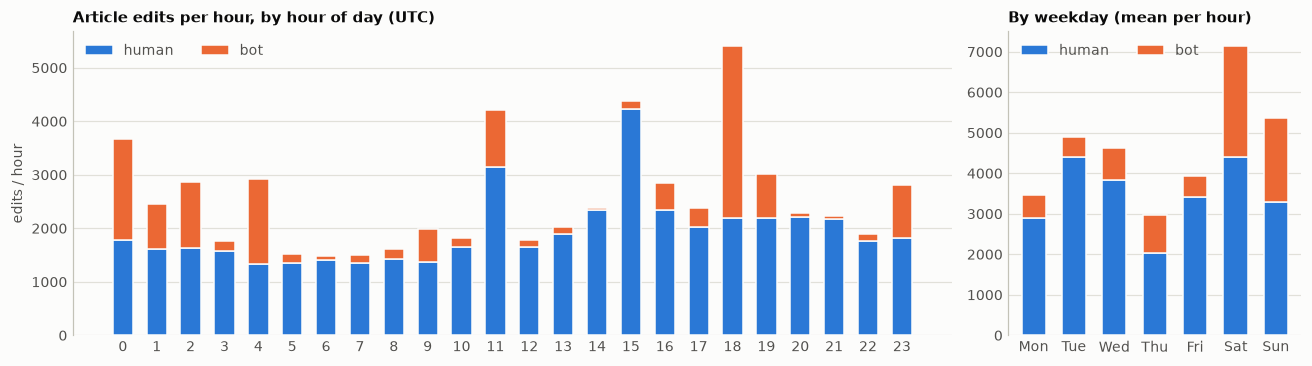

In [2]:
edits = ea.edits_frame(c)
win = edits[edits["window"] >= 0]
by_hour, by_day = ea.volume(edits, "hour"), ea.volume(edits, "weekday")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4), width_ratios=[3, 1])
ep.stacked_columns(a1, by_hour, "Article edits per hour, by hour of day (UTC)", "edits / hour")
ep.stacked_columns(a2, by_day, "By weekday (mean per hour)")
fig.tight_layout()
display(by_hour.T.round(0), by_day.T.round(0))

,edits,reverts,share_of_edits,share_of_reverts,revert_rate
kind,,,,,
anonymous,5.0,5.0,4.391e-05,8.757e-04,1.000
bot,28334.0,50.0,2.488e-01,8.757e-03,0.002
registered,73131.0,2628.0,6.423e-01,4.602e-01,0.036
temporary,12392.0,3027.0,1.088e-01,5.301e-01,0.244


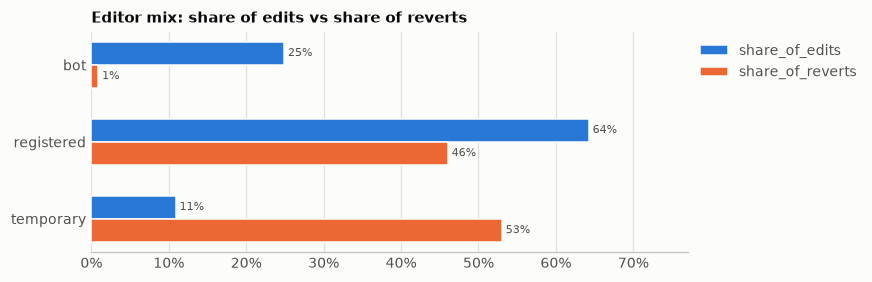

In [3]:
mix = ea.rate_table(win, "kind")
fig, ax = plt.subplots(figsize=(7, 2.6))
shares = mix.loc[mix["edits"] >= 30, ["share_of_edits", "share_of_reverts"]]
ep.grouped_hbars(ax, shares, "Editor mix: share of edits vs share of reverts")
mix

Revert rate (share of edits that carry `mw-reverted` at the snapshot), on **human content
edits**. These exclude bots, page creations, and edits that are themselves reverts. Edit count
comes from the diff sample, weighted back to the natural rate. Every other cut uses all listed
edits.

,edits,reverts,share_of_edits,share_of_reverts,revert_rate
kind,,,,,
anonymous,4.000,4.000,0.000,0.001,1.000
registered,67187.000,2159.000,0.849,0.431,0.032
temporary,11982.000,2852.000,0.151,0.569,0.238


,edits,reverts,share_of_edits,share_of_reverts,revert_rate
editcount,,,,,
1-9,8418.000,2588.000,0.106,0.516,0.307
10-99,8082.000,1080.000,0.102,0.215,0.134
100-999,10989.000,575.000,0.139,0.115,0.052
1k-9.9k,16383.000,421.000,0.207,0.084,0.026
10k+,35301.000,351.000,0.446,0.070,0.010


,edits,reverts,share_of_edits,share_of_reverts,revert_rate
size_bucket,,,,,
< -1k,838.000,192.000,0.011,0.038,0.229
-1k..-101,3978.000,313.000,0.050,0.062,0.079
-100..-1,16932.000,899.000,0.214,0.179,0.053
0,5934.000,277.000,0.075,0.055,0.047
1..100,35797.000,2391.000,0.452,0.477,0.067
101..1k,13431.000,765.000,0.170,0.153,0.057
> 1k,2263.000,178.000,0.029,0.035,0.079


,edits,reverts,share_of_edits,share_of_reverts,revert_rate
summary_present,,,,,
False,34457.000,2956.000,0.435,0.589,0.086
True,44716.000,2059.000,0.565,0.411,0.046


,edits,reverts,share_of_edits,share_of_reverts,revert_rate
device,,,,,
desktop,63817.000,3223.000,0.806,0.643,0.051
mobile app,1449.000,87.000,0.018,0.017,0.060
mobile web,13907.000,1705.000,0.176,0.340,0.123


,edits,reverts,share_of_edits,share_of_reverts,revert_rate
interface,,,,,
VisualEditor,19803.000,2844.000,0.250,0.567,0.144
other / none,22803.000,856.000,0.288,0.171,0.038
source editor (2010),36567.000,1315.000,0.462,0.262,0.036


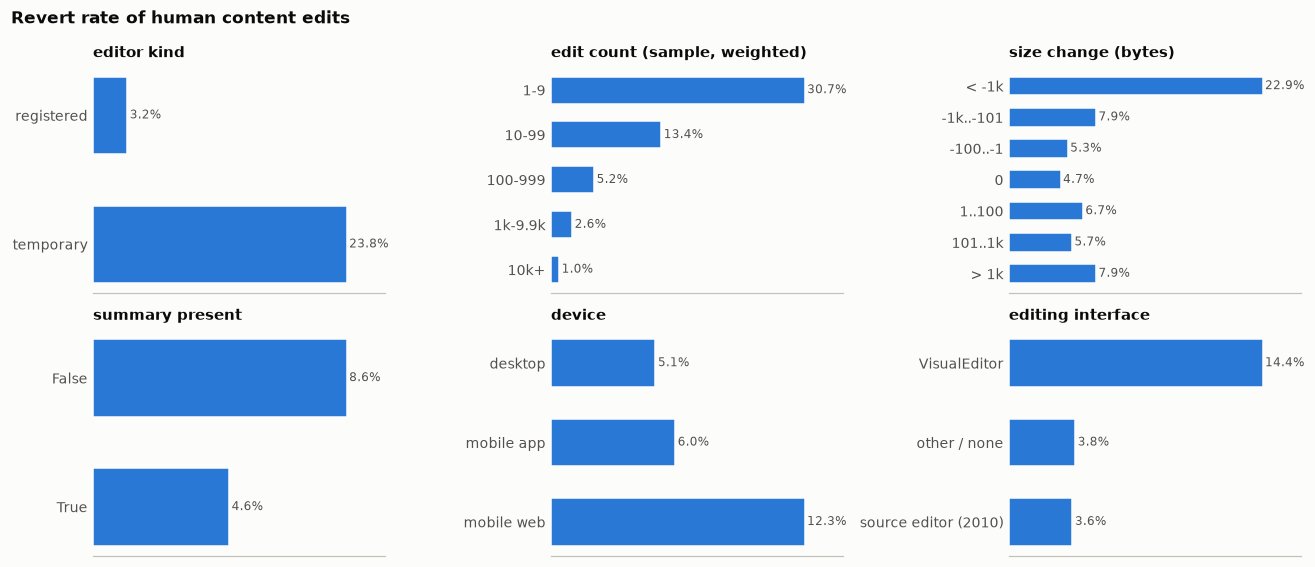

In [4]:
human = win[win["human_content"]]
sample = ea.sample_frame(c)
cuts = {
    "editor kind": ea.rate_table(human, "kind"),
    "edit count (sample, weighted)": ea.editcount_table(sample),
    "size change (bytes)": ea.rate_table(human, "size_bucket"),
    "summary present": ea.rate_table(human, "summary_present"),
    "device": ea.rate_table(human, "device"),
    "editing interface": ea.rate_table(human, "interface"),
}
rates = {k: t.loc[t["edits"] >= 30, "revert_rate"] for k, t in cuts.items()}
fig = ep.small_multiples(rates, "Revert rate of human content edits")
for name, table in cuts.items():
    display(table.style.set_caption(name).format(precision=3))

**Save-time tags.** The edit filter and the editing software tag an edit when it is saved, so
these are fair features. The live desk reads EventStreams `recentchange` events, which carry
**no tags**, so a model that uses tags needs one extra API call per edit in production.

,edits,revert_rate,rate_without
tag,,,
possible vandalism,119,8.319e-01,0.062
references removed,250,5.000e-01,0.062
editcheck-references,218,2.385e-01,0.063
mw-removed-redirect,131,2.061e-01,0.063
visualeditor,19803,1.436e-01,0.037
mw-new-redirect,73,1.370e-01,0.063
mobile web edit,13907,1.226e-01,0.051
mobile edit,15351,1.167e-01,0.051
editcheck-newcontent,986,1.126e-01,0.063


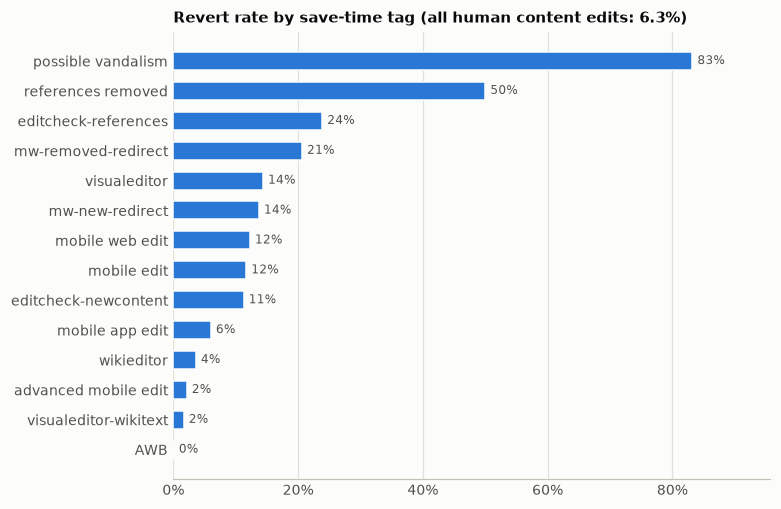

In [5]:
tags = ea.tag_rates(human)
fig, ax = plt.subplots(figsize=(7, 0.32 * len(tags) + 0.8))
ep.hbars(
    ax,
    tags["revert_rate"],
    f"Revert rate by save-time tag (all human content edits: {human['reverted'].mean():.1%})",
)
tags

## 2. Patrol behaviour

,human content reverts
reverts,5013.000
median_min,33.033
p90_min,4078.250
within_10_min,0.407
within_1_h,0.542
within_3_h,0.650
within_24_h,0.831


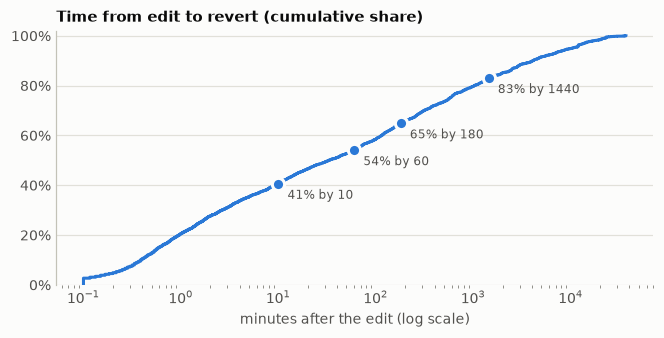

In [6]:
links = ea.links_frame(c, edits)
hl = links[links["human_content"] & (links["window"] >= 0)]
fig, ax = plt.subplots(figsize=(7, 3))
ep.ecdf(
    ax, hl["delay_min"], "Time from edit to revert (cumulative share)", "minutes after the edit (log scale)"
)
ea.delay_summary(hl).to_frame("human content reverts")

,count,50%,90%
tool,,,
twinkle,1289.0,70.900,2472.197
undo,1137.0,180.750,5461.303
manual,885.0,99.583,8319.430
rollback,570.0,122.617,11961.215
interceptor,320.0,0.725,3.617
other_tool,320.0,4.325,2489.510
cluebot,272.0,0.117,14.608
huggle,130.0,0.792,19.137
wikishield,90.0,1.025,7.370


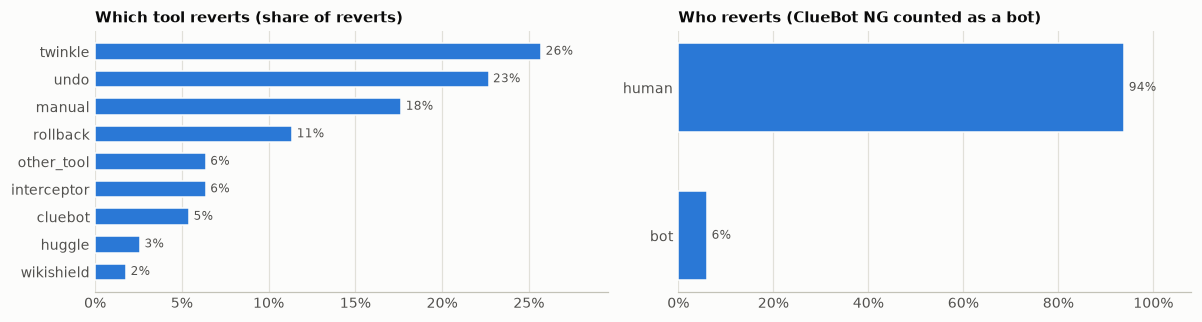

In [7]:
tools = hl["tool"].value_counts(normalize=True)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3))
ep.hbars(a1, tools, "Which tool reverts (share of reverts)")
who = hl["reverter_kind"].value_counts(normalize=True)
ep.hbars(a2, who, "Who reverts (ClueBot NG counted as a bot)")
fig.tight_layout()
hl.groupby("tool")["delay_min"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%"]].sort_values(
    "count", ascending=False
)

## 3. The reason taxonomy

`triage.intent.review_reason` reads the revert's edit summary. It first strips the tool
boilerplate ("Reverted N edits by X", "Undid revision N by X", tool tags), then looks for a reason.
The result is the **reviewer's stated reason**, not the editor's intent. `none` means the revert
gives no reason, and `other_stated` means it gives one the taxonomy does not cover.

,reverts,share,maps to (Sonnet's reasons)
reason,,,
none,1961,3.912e-01,other
other_stated,1295,2.583e-01,other
unsourced,659,1.315e-01,unsourced
vandalism,450,8.977e-02,vandalism
unexplained_removal,122,2.434e-02,other
pov,103,2.055e-02,pov
good_faith,101,2.015e-02,other
ban_evasion,101,2.015e-02,other
ai_generated,90,1.795e-02,other


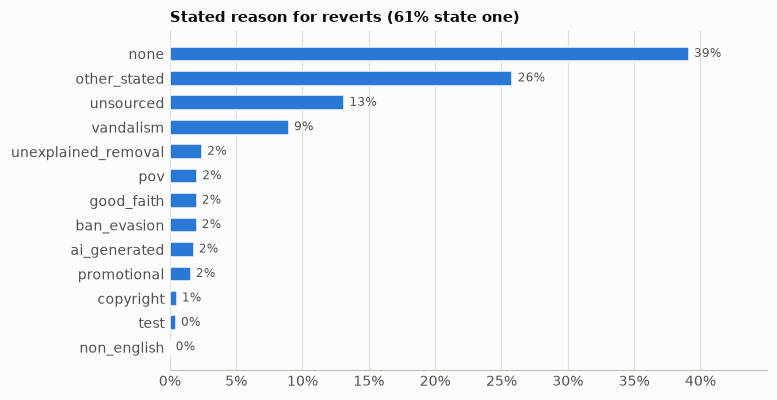

In [8]:
stated = hl["stated"].mean()
reasons = hl["reason"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(7, 4))
ep.hbars(ax, reasons, f"Stated reason for reverts ({stated:.0%} state one)")
pd.DataFrame(
    {
        "reverts": hl["reason"].value_counts(),
        "share": reasons,
        "maps to (Sonnet's reasons)": reasons.index.map(REVIEW_TO_WIKI),
    }
)

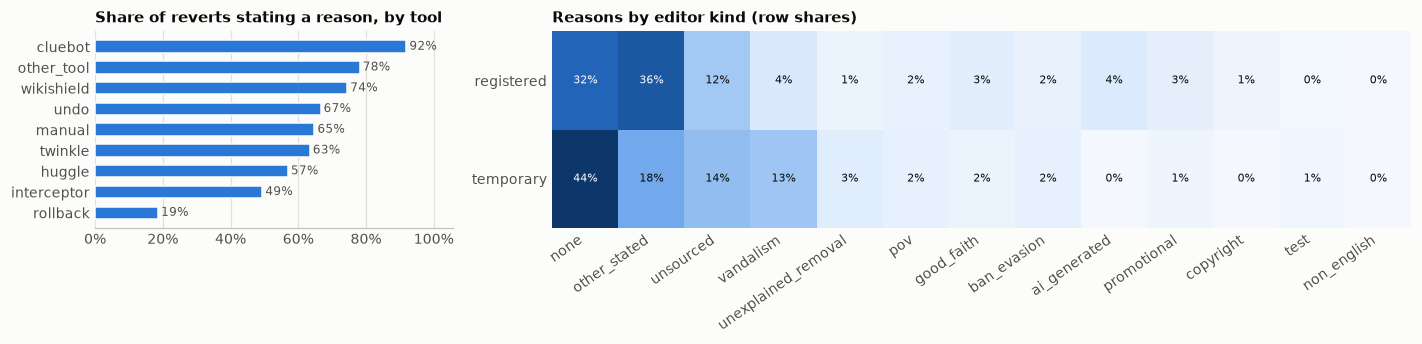

In [9]:
by_tool = hl.groupby("tool")["reason"].agg(lambda r: (r != "none").mean()).sort_values(ascending=False)
by_kind = ea.reasons_by_kind(hl, reasons.index)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.2), width_ratios=[1, 2.4])
ep.hbars(a1, by_tool, "Share of reverts stating a reason, by tool")
ep.heatmap(a2, by_kind, "Reasons by editor kind (row shares)")
fig.tight_layout()

**What editors say they did.** `triage.intent.declared_intent` reads the editor's own summary.
Section-only summaries (`/* History */`) and automatic ones ("Replaced content with…") count as
`none`.

reverted,kept,reverted
comment,,
none,0.425,0.589
formatting,0.141,0.045
copyedit,0.111,0.046
other,0.103,0.164
references,0.080,0.034
content,0.053,0.067
removal,0.046,0.027
update,0.040,0.027


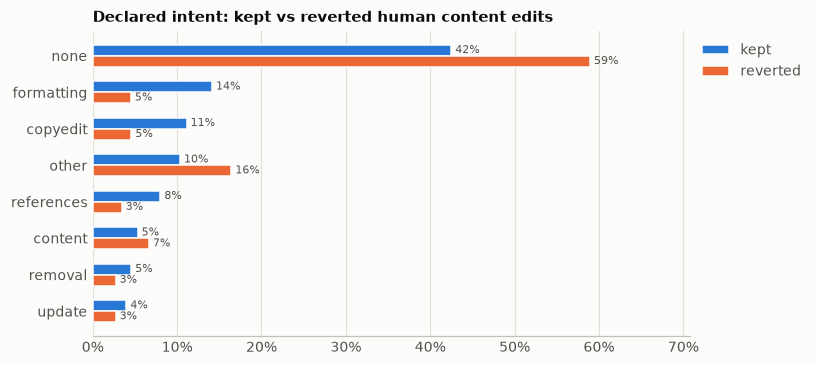

In [10]:
declared = ea.declared_shares(edits)
fig, ax = plt.subplots(figsize=(7, 3.6))
ep.grouped_hbars(ax, declared, "Declared intent: kept vs reverted human content edits")
declared

## 4. Models

The **time split** trains on the 16 earlier windows and tests on the 8 later ones, so the model
never sees an edit from the future of its test set. Each model has three variants:

- **tabular**: HistGradientBoosting on the features in `triage/features.py` (editor, size,
  added-text stats, markup counts, summary flags, save-time tags).
- **text**: TF-IDF character n-grams of the added text, then logistic regression.
- **blend**: the mean of the two.

**Leakage notes**

- `mw-reverted`, the reverting edit, and anything that happens after the save are never features.
  `tests/test_features.py` checks that the features are identical with and without the tag.
- The editor's edit count and registration are read when the corpus is built, days after the
  edit, so the count includes later edits. Edits made in the gap tend to be by the same editors
  who get blocked or reverted. The `tabular_no_editcount` row shows how much the model leans
  on it.
- Revision-deleted diffs (often the worst vandalism) return 403 and are missing from the sample,
  which biases it toward milder reverts.
- Model C predicts the editor's summary, so no summary feature is an input.

In [11]:
pd.crosstab(sample["split"], sample["reverted"].map({True: "reverted", False: "kept"}), margins=True)

reverted,kept,reverted,All
split,,,
live,817,44,861
test,1686,1642,3328
train,3313,3321,6634
All,5816,5007,10823


### A. Revert or keep

Scores are prior-corrected and metrics are weighted to the natural revert rate of human
content edits. `pr_auc_lo` and `pr_auc_hi` give a 95% bootstrap interval. The baselines are the base rate itself (PR-AUC equals the base rate for a random
ranking) and a one-rule model, `unregistered`, which scores 1 for a temporary account or IP
editor and 0 otherwise.

,n,n_reverted,base_rate,pr_auc,roc_auc,precision_at_recall_0.5,recall_at_precision_0.9,pr_auc_lo,pr_auc_hi
tabular,3328.0,1642.0,0.062,0.421,0.868,0.394,0.088,0.377,0.468
text,3328.0,1642.0,0.062,0.138,0.681,0.120,0.002,0.122,0.162
blend,3328.0,1642.0,0.062,0.387,0.860,0.366,0.063,0.347,0.435
tabular_no_editcount,3328.0,1642.0,0.062,0.414,0.855,0.361,0.081,0.373,0.462
unregistered,3328.0,1642.0,0.062,0.158,0.721,0.231,0.000,0.142,0.176


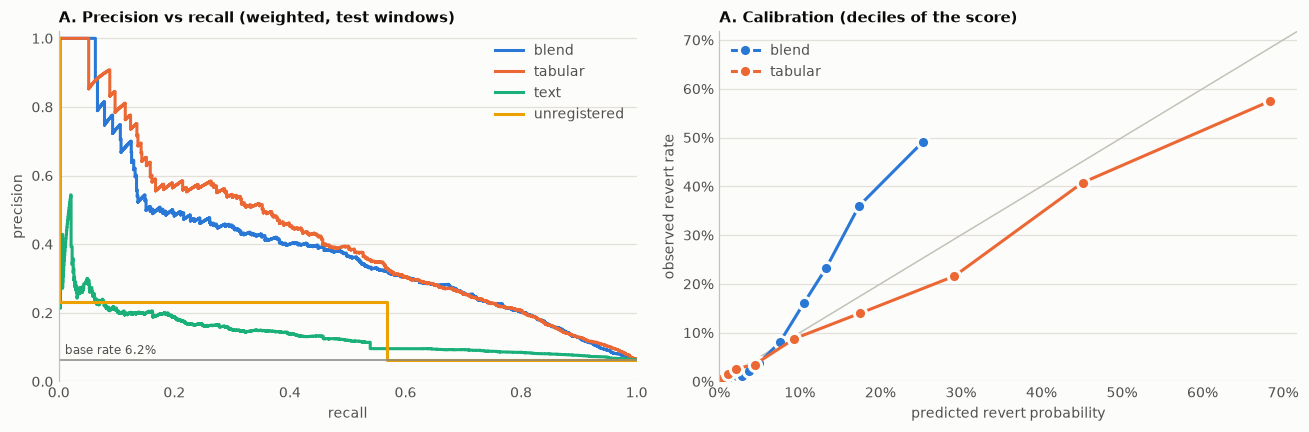

In [12]:
A = ev.revert_model(sample)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
curves = {k: A.extra["pr_curves"][k] for k in ["blend", "tabular", "text", "unregistered"]}
ep.pr_curves(
    a1, curves, A.metrics.loc["blend", "base_rate"], "A. Precision vs recall (weighted, test windows)"
)
ep.calibration_plot(a2, A.extra["calibration"], "A. Calibration (deciles of the score)")
fig.tight_layout()
A.metrics

### B. The reviewer's stated reason

This model uses reverted edits whose revert states a covered reason (`none` and `other_stated`
are excluded), and keeps only classes with at least 40 examples. Classes are balanced in
training. The baseline always predicts the commonest training class.

,n_test,accuracy,macro_f1
tabular,556.0,0.480,0.304
text,556.0,0.448,0.324
blend,556.0,0.491,0.309
majority,556.0,0.394,0.071


,tabular,text,blend,majority,n_train,n_test
ai_generated,0.275,0.525,0.302,0.000,61,27
ban_evasion,0.172,0.128,0.175,0.000,73,28
good_faith,0.000,0.045,0.000,0.000,71,26
pov,0.000,0.043,0.000,0.000,76,26
promotional,0.333,0.400,0.296,0.000,48,31
unexplained_removal,0.483,0.372,0.512,0.000,79,43
unsourced,0.587,0.496,0.598,0.565,438,219
vandalism,0.581,0.582,0.586,0.000,280,156


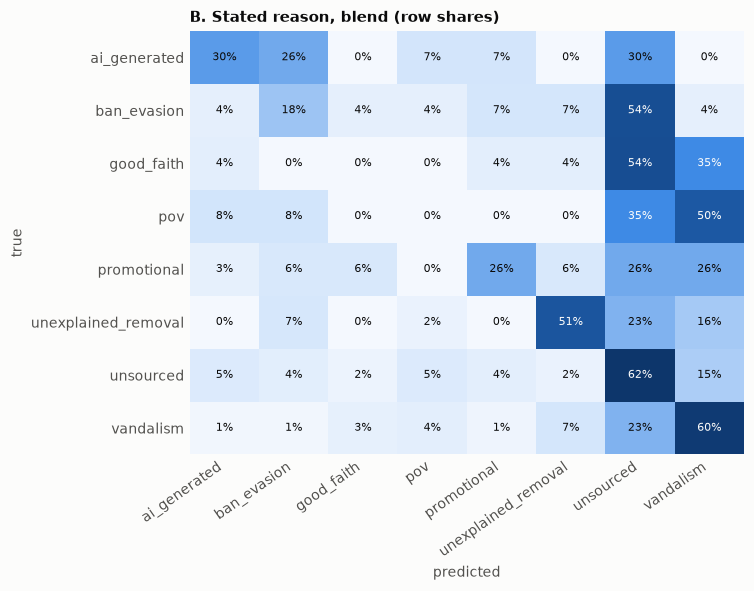

In [13]:
B = ev.reason_model(sample)
fig, ax = plt.subplots(figsize=(6.5, 5))
r = B.extra["results"]["blend"]
ep.confusion(ax, r["confusion"], r["labels"], "B. Stated reason, blend (row shares)")
display(B.metrics, B.extra["per_class"])

### C. The editor's declared intent

This model uses kept edits that declare a covered type, predicting the editor's own label from
the diff alone.

,n_test,accuracy,macro_f1
tabular,819.0,0.505,0.467
text,819.0,0.510,0.445
blend,819.0,0.546,0.502
majority,819.0,0.282,0.073


,tabular,text,blend,majority,n_train,n_test
content,0.379,0.275,0.385,0.00,182,85
copyedit,0.557,0.545,0.603,0.00,367,181
formatting,0.579,0.571,0.611,0.44,490,231
references,0.503,0.699,0.578,0.00,258,174
removal,0.415,0.179,0.432,0.00,164,83
update,0.370,0.400,0.407,0.00,136,65


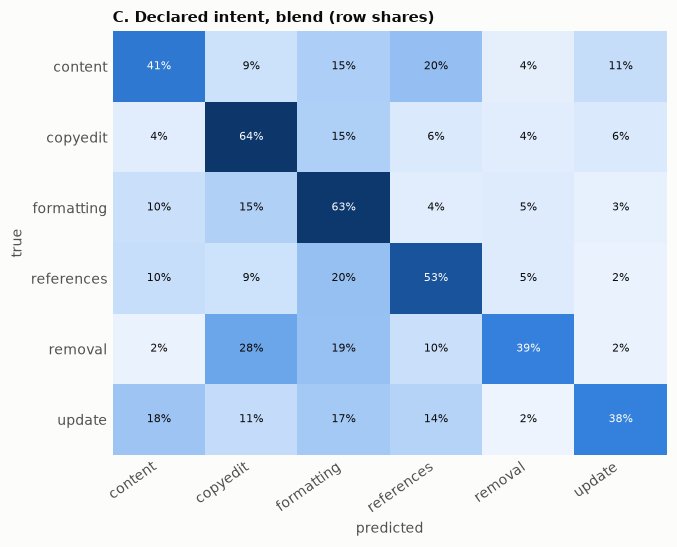

In [14]:
C = ev.declared_model(sample)
fig, ax = plt.subplots(figsize=(6.5, 5))
r = C.extra["results"]["blend"]
ep.confusion(ax, r["confusion"], r["labels"], "C. Declared intent, blend (row shares)")
display(C.metrics, C.extra["per_class"])

## 5. Comparisons

**Lift Wing.** Wikimedia's free `revertrisk-language-agnostic` model (no key) scored a seeded
random subset of the test-window sample. The local models are scored on the same edits, and the
metrics are weighted to the natural rate. Lift Wing latency is the measured round trip from here.
The local figure is the time to score a batch, divided by its size.

In [15]:
lw = ev.liftwing_comparison(A, c["liftwing"])
lw.metrics

,n,n_reverted,base_rate,pr_auc,roc_auc,precision_at_recall_0.5,recall_at_precision_0.9,pr_auc_lo,pr_auc_hi,median_ms_per_edit
liftwing,400.0,199.0,0.063,0.312,0.867,0.301,0.050,0.237,0.465,378.500
blend,400.0,199.0,0.063,0.464,0.887,0.440,0.136,0.365,0.613,0.351
tabular,400.0,199.0,0.063,0.485,0.902,0.409,0.095,0.377,0.652,0.351
text,400.0,199.0,0.063,0.127,0.675,0.116,0.000,0.092,0.216,0.351


**Sonnet via Mubit.** These are the live desk's logged keep/revert verdicts
(`data/calls.sqlite`), judged seconds after each save. Truth is the `mw-reverted` tag at the corpus
snapshot, only a few hours after those edits. The delay distribution above shows what share of
eventual reverts have happened by then, so some "kept" edits will still be reverted, which
understates both models' precision about equally. The local model is the blend trained on
the corpus's train windows. It flags its top-scored edits at Sonnet's own flag rate, so the
precision and recall are like-for-like. Sonnet's ranking score is its verdict times its stated
confidence. Cost uses the list price in `triage/config.py`, and the local model is free.

In [16]:
so = ev.sonnet_comparison(A, sample, c["live_calls"])
print(f"edits judged by both: {len(so.test)}; reverted at snapshot: {int(so.test['reverted'].sum())}")
print(f"share of eventual reverts that happen within 3 h: {(hl['delay_min'] <= 180).mean():.0%}")
so.metrics

edits judged by both: 861; reverted at snapshot: 44
share of eventual reverts that happen within 3 h: 65%


,n,n_reverted,flag_rate,precision,recall,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,median_ms_per_edit,usd_per_1k_edits
sonnet,861.0,44.0,0.134,0.278,0.727,0.435,0.285,0.575,0.875,1719.000,2.909
local,861.0,44.0,0.134,0.261,0.682,0.334,0.225,0.490,0.865,0.276,0.000


Sonnet's reason against the reference label, both mapped onto `WIKI_REASONS`. The
reference is the reviewer's stated reason for reverted edits and the editor's declared type for
kept ones. Only edits with an informative reference label are counted.

sonnet_reason,constructive,copyedit,vandalism,promotional,unsourced,test_edit,pov,other
wiki_reason,,,,,,,,
constructive,151,10,0,1,10,0,0,5
copyedit,116,61,1,0,3,0,0,7
vandalism,0,0,2,0,0,0,0,0
unsourced,1,0,0,0,7,0,0,1
other,3,0,1,0,2,0,0,2


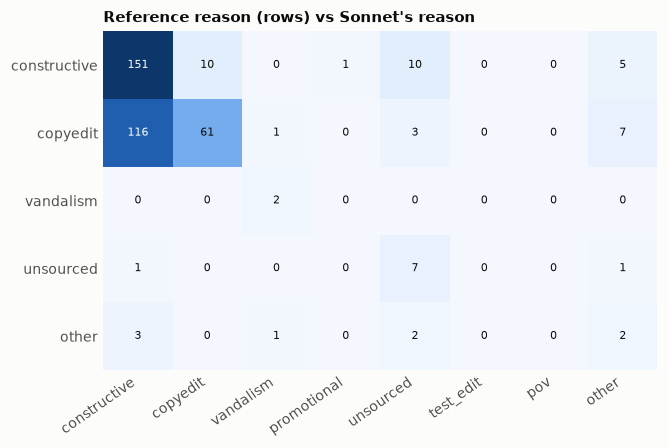

In [17]:
agree = so.extra["reasons"]
if len(agree):
    fig, ax = plt.subplots(figsize=(6.5, 0.5 * len(agree) + 1.5))
    ep.heatmap(ax, agree, "Reference reason (rows) vs Sonnet's reason", "{:.0f}")
agree

## 6. Can we classify intention?

**Not directly, because no label here measures intention.** What can be classified are three
observable proxies, and each answers a narrower question.

**1. Will a patroller revert this edit? Yes, usefully, from save-time data alone.**
- **Base rate.** 6.3% of human content edits are reverted (5,015 of 79,173).
- **Who gets reverted.** Edit count and editor kind carry most of the signal. Temporary accounts
  make 15% of these edits but 57% of the reverts: 23.8% of their edits are reverted, against
  3.2% for registered editors. The rate falls from 31% at 1–9 edits to 1% at 10k+ edits.
- **Local tabular model, on the 8 later windows.**
  - PR-AUC 0.42 (95% CI 0.38–0.47), against the 0.062 base rate and 0.16 for the one-rule
    "not registered" baseline.
  - ROC-AUC 0.87, and precision 0.39 at half the reverts caught.
  - Removing the post-save edit count costs little: PR-AUC drops to 0.41.
  - **Weakness:** high-precision patrolling is out of reach. At 90% precision it finds only 9%
    of reverts.
- **Text n-gram model.** Weak on its own (PR-AUC 0.14). Averaged into the blend, it lowers
  PR-AUC to 0.39 and miscalibrates the scores.
- **Against Lift Wing's revertrisk-language-agnostic** (n = 400, 199 reverted), the local
  tabular model matches or beats it: PR-AUC 0.49 against 0.31 (the intervals overlap slightly),
  at about 0.3 ms against 380 ms per edit.
- **Against the live desk's Sonnet verdicts** (n = 861, only 44 reverted at the snapshot):
  - At Sonnet's own 13.4% flag rate, Sonnet scores precision 0.28 and recall 0.73. The local
    model scores 0.26 and 0.68.
  - PR-AUC is 0.44 for Sonnet (0.29–0.58) against 0.33 for local (0.23–0.49). The intervals
    overlap.
  - **Cost:** Sonnet takes a median 1.7 s and costs about $2.91 per 1,000 edits. The local model
    is free.
  - **Caveat:** the snapshot comes only hours after those edits, and only 65% of eventual
    reverts happen within 3 hours. Both models' precision is understated.

**2. Why did the patroller revert it? Only partly.**
- **Coverage.**
  - 39% of reverts state no reason at all. Rollback, Huggle and Interceptor are mostly silent.
  - 26% give free text that falls outside the taxonomy.
  - So only 35% carry a reason that can be classified.
- **Distribution of reasons.** Unsourced content 13% of all reverts, vandalism 9%, unexplained
  removal 2.4%, then about 2% each for POV/BLP, good faith, ban evasion and AI-generated text,
  1.6% promotional, and under 1% each for copyright, test edits and non-English text.
- **Model B results.** On the 8 classes with 40 or more examples, the model reaches macro F1
  0.31 (accuracy 0.49), against 0.07 (0.39) for always guessing "unsourced".
- **What is separable.**
  - Vandalism, unsourced and unexplained removal: F1 0.51–0.60.
  - AI-generated text: 0.53 with the text model.
  - Promotional: 0.40 with the text model.
- **What is not.** Ban evasion (0.18), POV (0) and good faith (0) cannot be told apart. They
  depend on who the editor is or on the article's sourcing, not on the diff. Vandalism and
  unsourced absorb most of the errors.

**3. What did the editor say they were doing? Moderately, for kept edits.**
- **Coverage.** 42% of kept edits have no summary, or only a section heading. Another 10% have a
  summary the regexes do not cover.
- **Model C results.** Predicting the declared type from the diff alone gives macro F1 0.50
  (accuracy 0.55), against 0.07 (0.28) for the majority class.
- **Per type.** Formatting, copyedit and references reach F1 0.58–0.61; the text model gets 0.70
  on references. Content additions, removals and updates are harder, at 0.39–0.43.
- **Agreement with Sonnet.** On the live edits with an informative reference label, Sonnet's
  reason agrees with the mapped reference 58% of the time (223 of 384). Most disagreements come
  from Sonnet calling a declared copyedit "constructive".

**In short:** the revert outcome is predictable, cheaply and locally, at the level of a ranked
patrol queue rather than an automatic verdict. Reasons and declared types are readable from the
diff only for the mechanical classes: vandalism, unsourced, removal, references, formatting and
copyedit. Those labels are a reviewer's terse justification, or an editor's self-description,
for at most about a third of reverts and about half of kept edits. They are noisy proxies for
intent, and good faith versus bad faith is exactly the part the data does not label.
